Simple Agent Graph and Managing States

In [2]:
from typing import TypedDict
class State_with_messages(TypedDict):
    messages: str
    

Nodes

Because the state is a TypedDict with schema as defined above, each node can access the key, messages, with state['messages'].

Each node returns a new value of the state key messages.

By default, the new value returned by each node will overwritethe prior state value.

In [3]:
def node1(state: State_with_messages) -> State_with_messages:
    print("---Node 1---")
    # Access the messages key from the state
    current_messages = state['messages']
    
    # Update the messages key with a new value
    new_messages = current_messages + " Node 1 executed."
    
    # Return the updated state
    return {'messages': new_messages}

Edges

Edges connect the nodes.

Normal Edges are used if you want to always go from, for example, node_1 to node_2.

Build the Graph with Nodes and Edges and the State

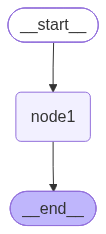

In [4]:
from langgraph.graph import StateGraph, START, END
from IPython.display import display, Image, Markdown
#Building the graph
builder = StateGraph(State_with_messages)
builder.add_node('node1', node1)
# Logic to add Edges to the graph
builder.add_edge(START, 'node1')    
builder.add_edge('node1', END)
#ADDING GRAPH VISUALIZATION
graph = builder.compile()
#View the graph
# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [5]:
graph.invoke({"messages": "Hi, how are you?."})

---Node 1---


{'messages': 'Hi, how are you?. Node 1 executed.'}

State Schema with multiple attributes

You can define your own state schema with multiple fields and manipulate them inside the graph as shown below

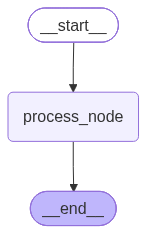

In [10]:
# Define the state structure
class State(TypedDict):
    data: str
    count: int


# Define a node that processes the state
def Process_State(state: State) -> State:
    # Example processing logic
    print(f"Current data: {state['data']}, count: {state['count']}")
    new_data = state['data'].upper()  # Convert data to uppercase
    new_count = state['count'] + 1     # Increment count
    return {'data': new_data, 'count': new_count}


# Initialize the StateGraph with the state schema
graph_builder = StateGraph(State)

# Add nodes and edges to your graph
graph_builder.add_node('process_node', Process_State)
graph_builder.add_edge(START, 'process_node')
graph_builder.add_edge('process_node', END)

#Compile the graph
graph = graph_builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))




In [14]:
# Execute the graph with an initial state
result = graph.invoke({"data": "hello world", "count": 0})

# Print the result
print("Final State:", result)

Current data: hello world, count: 0
Final State: {'data': 'HELLO WORLD', 'count': 1}


Graph with multiple processing nodes
So far we have built a graph with one node, lets now build one with three processing nodes and update (and overwrite) the overall state of the agent in each node

In [15]:
class State_with_multiple_processingNodes(TypedDict):
    messages: str

In [ ]:
def node1(state: State_with_messages) -> State_with_messages:
    print("---Node 1---")
    state = state['messages']
    return {"messages": "Hello this is node 1"}


def node2(state: State_with_messages) -> State_with_messages:
    print("---Node 2---")
    state = state['messages']
    return {"messages": "Hello this is node 2"}


def final_node(state: State_with_messages) -> State_with_messages:
    print("---Node 3---")
    state = state['messages']
    return {"messages": "Hello this is node 3"}

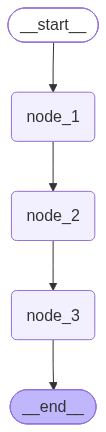

In [22]:
# Build graph
builder = StateGraph(State_with_multiple_processingNodes)
builder.add_node("node_1", node1)
builder.add_node("node_2", node2)
builder.add_node("node_3", final_node)

# Logic
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", "node_3")
builder.add_edge("node_3", END)


# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [24]:
graph.invoke({"messages": "Hi, how are you?."})

---Node 1---
---Node 2---
---Node 3---


{'messages': 'Hello this is node 3'}

The state gets overwritten each time in each node which is something which we do not want. We want the agent to be aware of what is happening in each node and store all the intermediate messages also.

Imagine a tool call happening only to get overwritten by something else!

This is where reducer functions can be used to update and append to the overall agent's state schema instead of overwriting

Reducer- Graph with multiple processing nodes

So far we have built a graph with one node, lets now build one with three processing nodes and update the overall state of the agent in each node without overwriting the overall state

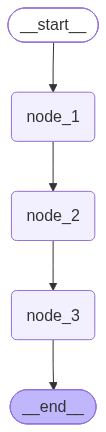

In [31]:
from typing import Annotated
from langgraph.graph.message import add_messages
class State_with_multiple_processingNodes(TypedDict):
    messages: Annotated[list, add_messages]## the reducer helps in appending to the state

def node_1_df(state: State_with_multiple_processingNodes) -> State_with_multiple_processingNodes:
    print("---Node 1---")
    state = state['messages']
    return {"messages": "Hello this is node 1"}

def node_2_df(state):
    print("---Node 2---")
    state = state['messages']
    return {"messages": "Hello this is node 2"}

def final_node_df(state):
    print("---Node 3---")
    state = state['messages']
    return {"messages": "Hello this is the final node"}

# Build graph
builder = StateGraph(State_with_multiple_processingNodes)
builder.add_node("node_1", node_1_df)
builder.add_node("node_2", node_2_df)
builder.add_node("node_3", final_node_df)

# Logic
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", "node_3")
builder.add_edge("node_3", END)


# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
response = graph.invoke({"messages": "Hi, how are you?."})
response

---Node 1---
---Node 2---
---Node 3---


{'messages': [HumanMessage(content='Hi, how are you?.', additional_kwargs={}, response_metadata={}, id='a8d45f22-fb2d-4247-8dc7-065e1c33bec9'),
  HumanMessage(content='Hello this is node 1', additional_kwargs={}, response_metadata={}, id='9a7e3a36-92d5-46b9-aa1d-6fe35ac8e4ac'),
  HumanMessage(content='Hello this is node 2', additional_kwargs={}, response_metadata={}, id='9c7d494e-400a-4e5c-8efd-294fa8c1e1cc'),
  HumanMessage(content='Hello this is the final node', additional_kwargs={}, response_metadata={}, id='f6b74927-49de-4a62-b1df-bf57ce819dff')]}

In [33]:
response['messages'][-1]

HumanMessage(content='Hello this is the final node', additional_kwargs={}, response_metadata={}, id='f6b74927-49de-4a62-b1df-bf57ce819dff')